# 01 - Data understanding and EDA
**Project:** Sri Lankan mobile phone price prediction with ensemble learning (CM4371).
**Goal of this notebook:** understand the raw 5,158-row CSV *before* modelling: structure, missing values, data quality problems and what drives price.

The target is the **advertised / catalogue price in LKR**: ikman.lk values are sellers' asking prices, Dialog values are retail catalogue prices. It is *not* a confirmed sold price.


In [1]:
import sys, warnings
sys.path.append("..")                      # lets the notebook import the reusable code in ../src
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, preprocess as P, models as M
from src.evaluate import regression_metrics, permutation_table
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
config.PLOT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the raw CSV (never modified)
loads the original mobile phone dataset and examines its basic structure. checks the number of records, available columns, data types, and missing values to understand the quality of the raw data.

In [16]:
raw = pd.read_csv(config.RAW_CSV)
print("rows, columns:", raw.shape)
raw.head()

rows, columns: (5158, 19)


,id,title,brand,model,price,price_raw,condition,storage,ram,location,description,detail_brand,detail_model,detail_condition,seller_name,posted_date,ad_url,is_member,is_featured
0,1,Apple iPhone 15 (Brand New),Apple,iPhone 15,200000,"Rs 200,000",Brand New,NaN,NaN,Kandy,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-15-brand-n...,True,False
1,2,Samsung Galaxy A56 5G 8GB 256GB (Brand New),Samsung,Galaxy A56 5G 8GB 256GB,95989,"Rs 95,989",Brand New,256GB,8GB,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/samsung-galaxy-a56-5g-8...,True,False
2,3,Apple iPhone 14 128GB (Used),Apple,iPhone 14 128GB,119999,"Rs 119,999",Used,128GB,NaN,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-14-128gb-u...,True,True
3,4,Infinix Hot 60i 128GB 6GBRam Blue (Brand New),Infinix,Hot 60i 128GB 6GBRam Blue,39990,"Rs 39,990",Brand New,128GB,6GB,Colombo,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/infinix-hot-60i-128gb-6...,True,False
4,5,Apple iPhone 14 Pro (Used),Apple,iPhone 14 Pro,170000,"Rs 170,000",Used,NaN,NaN,Kurunegala,NaN,NaN,NaN,NaN,NaN,NaN,https://ikman.lk/en/ad/apple-iphone-14-pro-use...,False,False


In [17]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5158 entries, 0 to 5157
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                5158 non-null   int64  
 1   title             5158 non-null   str    
 2   brand             5158 non-null   str    
 3   model             5158 non-null   str    
 4   price             5158 non-null   int64  
 5   price_raw         5158 non-null   str    
 6   condition         5158 non-null   str    
 7   storage           3354 non-null   str    
 8   ram               450 non-null    str    
 9   location          5157 non-null   str    
 10  description       0 non-null      float64
 11  detail_brand      0 non-null      float64
 12  detail_model      0 non-null      float64
 13  detail_condition  0 non-null      float64
 14  seller_name       0 non-null      float64
 15  posted_date       0 non-null      float64
 16  ad_url            5158 non-null   str    
 17  is_mem

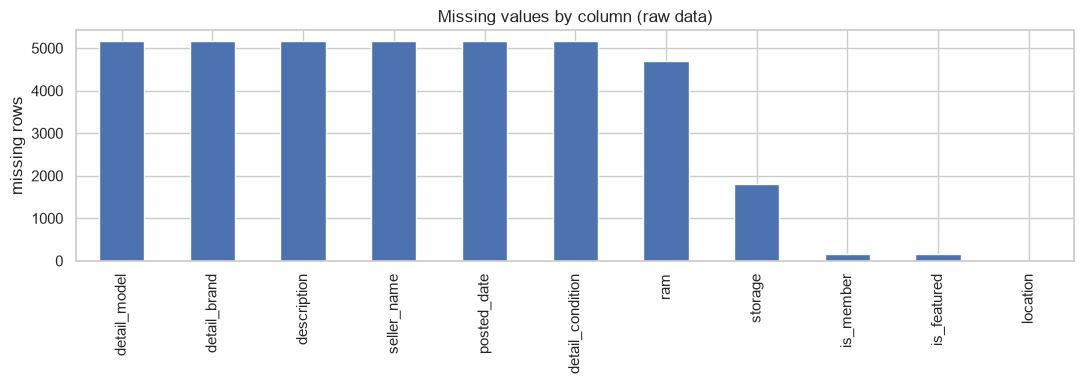

In [18]:
miss = raw.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss.plot(kind="bar", figsize=(11, 4), color="#4C72B0")
plt.title("Missing values by column (raw data)"); plt.ylabel("missing rows"); plt.tight_layout()
plt.savefig(config.PLOT_DIR / "01_missing_values.png", dpi=150); plt.show()

## 2. Which rows are ikman and which are Dialog?
This section identifies the source of each mobile phone record using its advertisement URL. It separates ikman and Dialog records and checks any records that could not be identified automatically.

In [19]:
src_guess = P.derive_source(raw)
print(src_guess.value_counts())
raw[src_guess == "Unknown"][["id", "title", "price", "condition", "location", "ad_url"]].head(15)

ikman     5124
Dialog      34
Name: count, dtype: int64


,id,title,price,condition,location,ad_url


## 3. RAM / storage quality check
This section checks the RAM and storage values in the dataset. Some records may have incorrect or swapped values, so the specifications are re-extracted from the available phone details to improve data accuracy.

In [20]:
parsed = pd.DataFrame(
    [P.parse_specs(r.get("title"), r.get("model"), r.get("storage"), r.get("ram"), r.get("detail_model"))
     for _, r in raw.iterrows()], columns=["ram_gb", "storage_gb"], index=raw.index)
csv_storage = pd.to_numeric(raw["storage"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
wrong = raw[(csv_storage <= 24)].join(parsed)
print(f"{len(wrong)} rows where the CSV 'storage' value is <= 24GB (probably RAM)")
wrong[["title", "storage", "ram", "ram_gb", "storage_gb"]].head(12)

964 rows where the CSV 'storage' value is <= 24GB (probably RAM)


,title,storage,ram,ram_gb,storage_gb
13,Realme C51 (4+4GB/128GB) (Used),4GB,4GB,4.00,128.00
25,Tecno Pop 7 (2+2GB/64GB) (Used),2GB,2GB,2.00,64.00
28,Google Pixel 7 8GB|128GB|50MP (Brand New),8GB,8GB,8.00,128.00
29,Vivo X300 Pro 16GB 512GB (Used),16GB,NaN,16.00,512.00
35,Samsung Galaxy S24 Ultra 12GB | 512GB (Brand New),12GB,12GB,12.00,512.00
42,Samsung Galaxy S25 Plus 12GB | 256GB (Brand New),12GB,12GB,12.00,256.00
46,Samsung Galaxy S25 12GB | 256GB (Brand New),12GB,12GB,12.00,256.00
48,Samsung Galaxy S25 FE 8GB | 256GB (Brand New),8GB,8GB,8.00,256.00
59,LG Q52 4GB 64GB (Used),4GB,NaN,4.00,64.00
60,Samsung Galaxy A17 5G 8GB+256GB (Brand New),8GB,NaN,8.00,256.00


In [21]:
print("parsed RAM missing    :", parsed["ram_gb"].isna().mean().round(3))
print("parsed storage missing :", parsed["storage_gb"].isna().mean().round(3))

parsed RAM missing    : 0.767
parsed storage missing : 0.351


## 4. Clean in memory for EDA
This section applies the data-cleaning process to prepare the dataset for exploratory data analysis. It handles incorrect specifications and source information while keeping the original CSV unchanged.

The full, saved cleaning (with the step-by-step row counts) is in notebook 02; here the same function is used so the EDA plots use correct RAM, storage and source values.

In [22]:
df, report = P.clean_dataset(raw, blank_url_source=config.BLANK_URL_SOURCE)
display(report) if "display" in globals() else print(report)
print(df.shape)
df.describe(include="all").T

27 suspicious prices flagged (kept unless drop_suspicious=True).
                      step  rows_after
0                 raw file        5158
1       drop missing price        5158
2          drop price <= 0        5158
3  drop duplicate listings        4432
4      final clean dataset        4432
(4432, 11)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,"4,432.00",NaN,NaN,NaN,"2,488.58","1,499.35",1.00,"1,179.75","2,439.50","3,771.25","5,158.00"
title,4432,2239,Apple iPhone 11 (Used),61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,4432,23,Apple,2079,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,4432,1099,apple iphone 11,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,4432,3,Used,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
storage_gb,"2,819.00",NaN,NaN,NaN,205.44,117.25,4.00,128.00,256.00,256.00,"1,024.00"
ram_gb,"1,119.00",NaN,NaN,NaN,7.94,3.28,1.00,6.00,8.00,10.00,24.00
location,4432,27,Colombo,2206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,4432,2,ikman,4398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,"4,432.00",NaN,NaN,NaN,"102,447.69","94,556.66","1,000.00","34,990.00","72,500.00","140,000.00","1,037,000.00"


## 5. Price distribution
This section explores the distribution of mobile phone prices in LKR. It compares the original price distribution with the log-transformed distribution to understand price variations and skewness.

skewness raw: 1.99 | log: -0.43


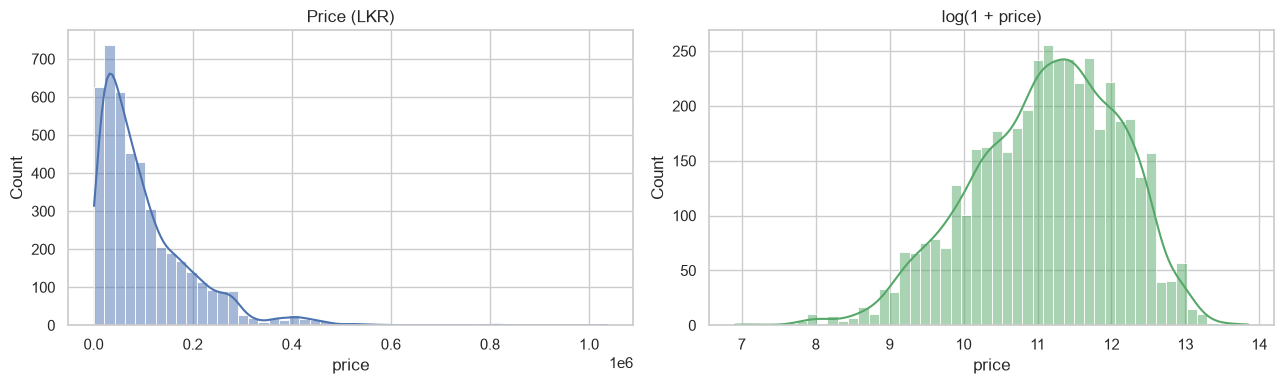

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=50, kde=True, ax=ax[0], color="#4C72B0"); ax[0].set_title("Price (LKR)")
sns.histplot(np.log1p(df["price"]), bins=50, kde=True, ax=ax[1], color="#55A868"); ax[1].set_title("log(1 + price)")
print("skewness raw:", round(df["price"].skew(), 2), "| log:", round(np.log1p(df["price"]).skew(), 2))
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_price_distribution.png", dpi=150); plt.show()

## 6. Brand, condition, RAM, storage, source
This section explores how different features relate to mobile phone prices. It examines brand, device condition, RAM, storage capacity, data source, and location to identify possible price patterns.

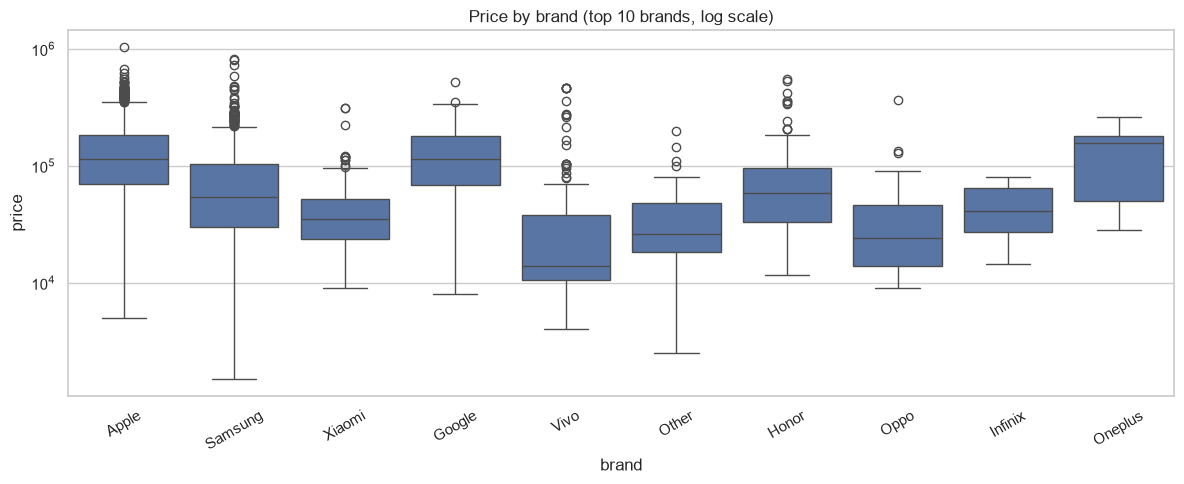

In [24]:
top = df["brand"].value_counts().head(10).index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df["brand"].isin(top)], x="brand", y="price", order=top)
plt.yscale("log"); plt.title("Price by brand (top 10 brands, log scale)"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_brand_vs_price.png", dpi=150); plt.show()

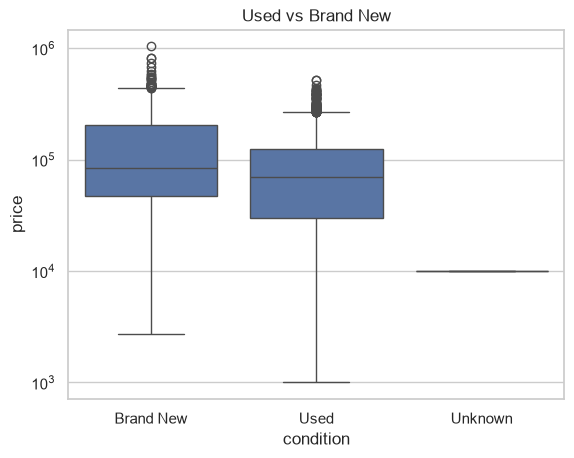

In [25]:
sns.boxplot(data=df, x="condition", y="price"); plt.yscale("log"); plt.title("Used vs Brand New")
plt.savefig(config.PLOT_DIR / "01_condition_vs_price.png", dpi=150); plt.show()

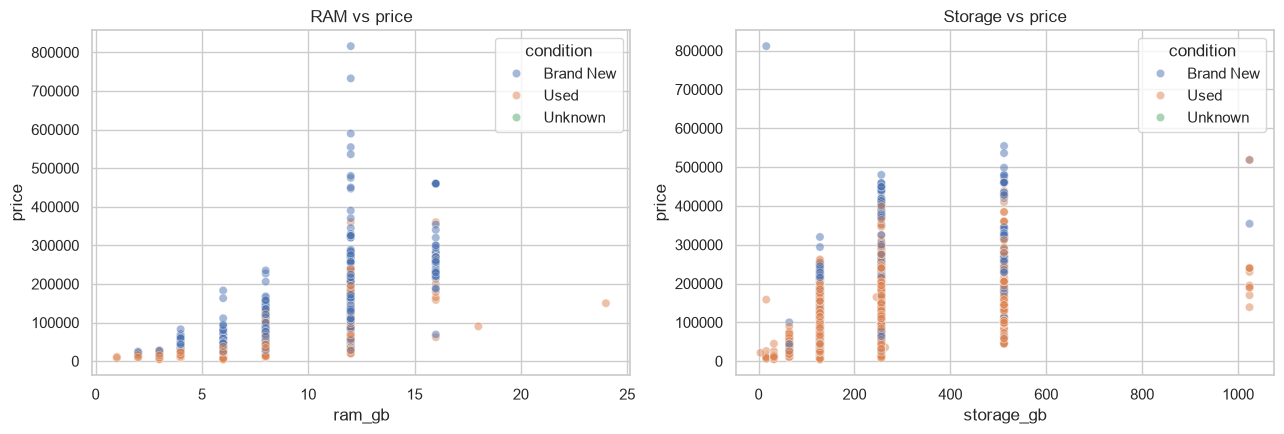

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="ram_gb", y="price", hue="condition", alpha=.5, ax=ax[0]); ax[0].set_title("RAM vs price")
sns.scatterplot(data=df, x="storage_gb", y="price", hue="condition", alpha=.5, ax=ax[1]); ax[1].set_title("Storage vs price")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_ram_storage_vs_price.png", dpi=150); plt.show()

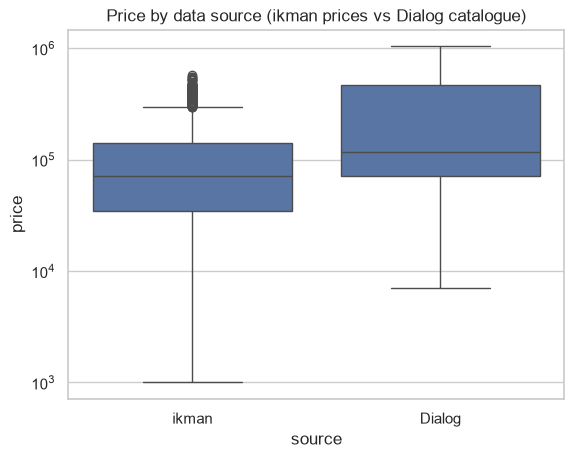

source
ikman     4398
Dialog      34
Name: count, dtype: int64
condition  Brand New   Unknown      Used
source                                  
Dialog    121,099.00       NaN 19,000.00
ikman      81,740.00 10,000.00 69,999.00


In [27]:
sns.boxplot(data=df, x="source", y="price"); plt.yscale("log"); plt.title("Price by data source (ikman prices vs Dialog catalogue)")
plt.savefig(config.PLOT_DIR / "01_source_vs_price.png", dpi=150); plt.show()
print(df["source"].value_counts())
print(df.groupby(["source", "condition"])["price"].median().unstack())

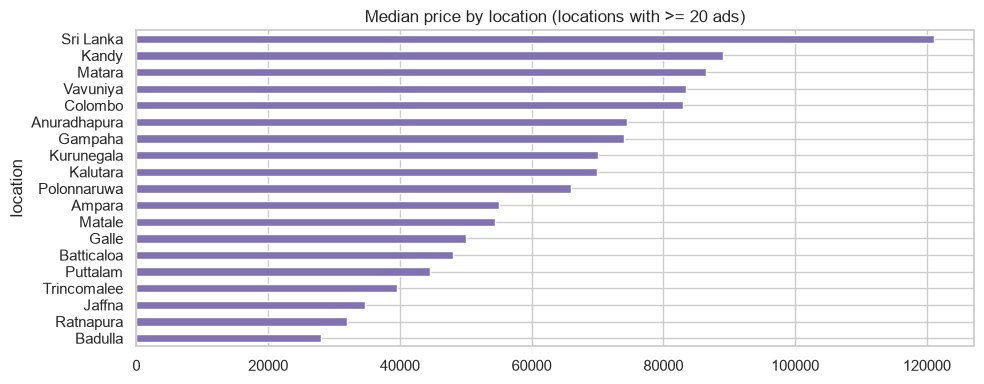

In [28]:
plt.figure(figsize=(10, 4))
loc_med = df.groupby("location")["price"].agg(["median", "size"]).query("size >= 20").sort_values("median")
loc_med["median"].plot(kind="barh", color="#8172B2"); plt.title("Median price by location (locations with >= 20 ads)")
plt.tight_layout(); plt.savefig(config.PLOT_DIR / "01_location_vs_price.png", dpi=150); plt.show()

## 7. Observations 